# Olist delivery experience: exploratory profiling

This is the exploration I did before fixing the metric definitions in `sql/02_transformations.sql` and
`src/olist_delivery/clean.py`. It profiles the nine raw files, checks the assumptions behind the late-delivery
rule and the review rule, and looks at the joins that can double count.

The raw CSVs are not in the repository. Set `OLIST_DATA_DIR` to their folder (or put them in `data/raw/`)
before running. Nothing here prints review text: comments are only counted.

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT / "src"))
from olist_delivery import clean, ingest
from olist_delivery.config import resolve_data_dir

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 72, "figure.figsize": (8, 3)})
DATA_DIR = resolve_data_dir()
print("raw folder found:", DATA_DIR.is_dir())

raw folder found: True


## 1. Files, row counts and version

In [2]:
check = ingest.check_sources(DATA_DIR, hashes=True)
pd.DataFrame({"rows": check.rows, "bytes": check.bytes})

,rows,bytes
customers,99441,9033957
geolocation,1000163,61273883
order_items,112650,15438671
order_payments,103886,5777138
order_reviews,100000,14409007
orders,99441,17654914
products,32951,2379446
sellers,3095,174703
category_translation,71,2613


In [3]:
print("version:", check.version)
print("total bytes:", f"{sum(check.bytes.values()):,}")
print("problems:", check.problems or "none")

version: github-mirror-2026-10-11
total bytes: 126,144,332
problems: none


The reviews file has 100,000 rows here, where Kaggle version 2 lists 99,224. The other eight files match.
This copy came from a GitHub mirror because Kaggle was not reachable, and its reviews file matches the
earlier 100,000-review release. Everything below is computed on this copy; the pipeline accepts either version.

In [4]:
raw = ingest.read_raw(DATA_DIR)
profile = pd.DataFrame({
    name: {"rows": len(df), "columns": df.shape[1], "cells_null_pct": round(df.isna().mean().mean() * 100, 2)}
    for name, df in raw.items()
}).T
profile

,rows,columns,cells_null_pct
customers,99441.0,5.0,0.00
geolocation,1000163.0,5.0,0.00
order_items,112650.0,7.0,0.00
order_payments,103886.0,5.0,0.00
order_reviews,100000.0,7.0,20.93
orders,99441.0,8.0,0.62
products,32951.0,9.0,0.83
sellers,3095.0,4.0,0.00
category_translation,71.0,2.0,0.00


## 2. Orders: status, timestamps and missing delivery dates

In [5]:
orders = clean.type_orders(raw["orders"])
status = orders.groupby("order_status").agg(
    orders=("order_id", "size"),
    has_delivered_date=("order_delivered_customer_date", lambda s: s.notna().sum()),
    has_carrier_date=("order_delivered_carrier_date", lambda s: s.notna().sum()),
).sort_values("orders", ascending=False)
status

,orders,has_delivered_date,has_carrier_date
order_status,,,
delivered,96478,96470,96476
shipped,1107,0,1107
canceled,625,6,75
unavailable,609,0,0
invoiced,314,0,0
processing,301,0,0
created,5,0,0
approved,2,0,0


Two things to handle explicitly rather than drop: 8 orders are marked `delivered` with no delivery date, and
6 canceled orders carry a delivery date. Timing metrics use status `delivered` with both dates present; the
other groups are counted in `mart.delivery_population`.

In [6]:
ts_cols = clean.ORDER_TS_COLUMNS
parsed = pd.DataFrame({c: [raw["orders"][c].notna().sum(), orders[c].notna().sum()] for c in ts_cols},
                      index=["present in raw", "parsed"]).T
parsed

,present in raw,parsed
order_purchase_timestamp,99441,99441
order_approved_at,99281,99281
order_delivered_carrier_date,97658,97658
order_delivered_customer_date,96476,96476
order_estimated_delivery_date,99441,99441


In [7]:
est = orders["order_estimated_delivery_date"]
print("estimates with a time of day other than midnight:", int((est != est.dt.normalize()).sum()))
print("purchase range:", orders["order_purchase_timestamp"].min(), "to", orders["order_purchase_timestamp"].max())
orders["order_purchase_timestamp"].dt.to_period("M").value_counts().sort_index().tail(6)

estimates with a time of day other than midnight: 0
purchase range: 2016-09-04 21:15:19 to 2018-10-17 17:30:18


order_purchase_timestamp
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64

Every estimate is stored at 00:00:00. If I compared timestamps, an order delivered at 3 pm on its estimated
day would count as late. So I compare calendar dates: late means delivered on a later day than the estimate.
The cell below shows how much that choice moves the rate.

In [8]:
d = clean.delivery_outcomes(orders)
t = d[d["in_timing_population"]]
print(f"timing population: {len(t):,} of {len(d):,} orders")
print(f"late by calendar date: {t['is_late'].astype(bool).mean():.2%}")
print(f"late by timestamp:     {t['is_late_timestamp_rule'].astype(bool).mean():.2%}")
print(f"delivered on the estimated day itself: {(t['days_vs_estimate'] == 0).sum():,}")

timing population: 96,470 of 99,441 orders
late by calendar date: 6.77%
late by timestamp:     8.11%
delivered on the estimated day itself: 1,292


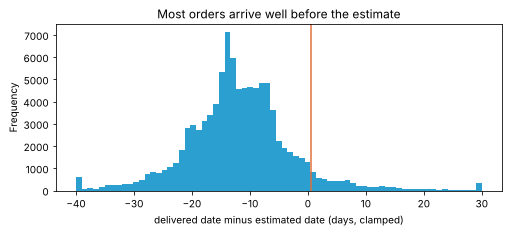

,promised_days,actual_days,days_vs_estimate
count,96470.0,96470.0,96470.0
mean,24.4,12.5,-11.9
std,8.8,9.6,10.2
min,3.0,0.0,-147.0
25%,19.0,7.0,-17.0
50%,24.0,10.0,-12.0
75%,29.0,16.0,-7.0
max,156.0,210.0,188.0


In [9]:
ax = t["days_vs_estimate"].astype(float).clip(-40, 30).plot.hist(bins=71, color="#2B9FD0")
ax.axvline(0.5, color="#E0703A")
ax.set_xlabel("delivered date minus estimated date (days, clamped)")
ax.set_title("Most orders arrive well before the estimate")
plt.show()
t[["promised_days", "actual_days", "days_vs_estimate"]].astype(float).describe().round(1)

In [10]:
legs = t[["seller_handling_days", "carrier_transit_days"]].astype(float)
print("orders where the hand-off date is out of order (legs left blank):", int(legs.isna().any(axis=1).sum()))
legs.describe().round(1)

orders where the hand-off date is out of order (legs left blank): 23


,seller_handling_days,carrier_transit_days
count,96447.0,96447.0
mean,3.2,9.3
std,3.6,8.8
min,0.0,0.0
25%,1.0,4.0
50%,2.0,7.0
75%,4.0,12.0
max,126.0,205.0


## 3. Reviews: duplicates, shared reviews and timing

In [11]:
reviews = clean.type_reviews(raw["order_reviews"])
print(f"rows {len(reviews):,}, distinct review_id {reviews['review_id'].nunique():,}, distinct order_id {reviews['order_id'].nunique():,}")
per_order = reviews.groupby("order_id").size().value_counts().sort_index().rename("orders")
per_review = reviews.groupby("review_id").size().value_counts().sort_index().rename("review_ids")
pd.concat([per_order, per_review], axis=1).rename_axis("count per key")

rows 100,000, distinct review_id 99,173, distinct order_id 99,441


,orders,review_ids
count per key,,
1,98886,98371
2,551,777
3,4,25


In [12]:
multi = reviews[reviews.groupby("order_id")["review_id"].transform("size") > 1]
differs = multi.groupby("order_id")["review_score"].nunique().gt(1)
print(f"orders with more than one review: {multi['order_id'].nunique():,}; scores differ in {int(differs.sum()):,}")
print("ties on answer timestamp within an order:",
      int(multi.duplicated(["order_id", "review_answer_timestamp"]).sum()))

orders with more than one review: 555; scores differ in 209
ties on answer timestamp within an order: 0


Some orders have two or three reviews with different scores, and about 800 review_ids are attached to more than
one order. I keep the latest answered review per order (then latest creation date, then review_id) and let a
shared review count for each order it belongs to. `test_rules.py` checks this rule on a fixture.

In [13]:
latest = clean.latest_review_per_order(reviews)
print("orders after de-duplication:", f"{len(latest):,}")
print("share with a written comment:", f"{latest['has_comment_message'].mean():.1%}")
latest["review_score"].value_counts(normalize=True).sort_index().round(3)

orders after de-duplication: 99,441
share with a written comment: 41.8%


review_score
1    0.119
2    0.032
3    0.083
4    0.192
5    0.574
Name: proportion, dtype: Float64

In [14]:
j = t.merge(latest[["order_id", "review_score", "review_creation_date", "review_answer_timestamp"]], on="order_id")
j["answered_before_delivery"] = j["review_answer_timestamp"] < j["order_delivered_customer_date"]
j["survey_sent_before_delivery"] = j["review_creation_date"] < j["order_delivered_customer_date"].dt.normalize()
j.groupby(j["is_late"].astype(bool).map({True: "late", False: "on time"}))[
    ["review_score", "answered_before_delivery", "survey_sent_before_delivery"]].mean().round(3)

,review_score,answered_before_delivery,survey_sent_before_delivery
is_late,,,
late,2.255,0.704,0.747
on time,4.279,0.002,0.003


The review survey (`review_creation_date`) often goes out before a late parcel arrives, and most late-order reviews
are answered before delivery. So a low score on a late order is partly a rating of the wait. That matters for
how the review gap is read.

In [15]:
by_bucket = j.groupby("delay_bucket").agg(orders=("order_id", "size"), avg_score=("review_score", "mean"),
                                        pct_1star=("review_score", lambda s: (s == 1).mean()))
order = [b[0] for b in __import__("olist_delivery.config", fromlist=["DELAY_BUCKETS"]).DELAY_BUCKETS]
by_bucket.loc[order].round(3)

,orders,avg_score,pct_1star
delay_bucket,,,
early_15plus,34939,4.315,0.067
early_8_14,36364,4.298,0.067
early_1_7,17341,4.189,0.073
on_day,1292,4.01,0.091
late_1_3,1870,3.282,0.253
late_4_7,1802,2.087,0.591
late_8_14,1478,1.666,0.706
late_15plus,1384,1.717,0.691


## 4. Items, sellers and payments: grain and fan-out

In [16]:
items = clean.type_items(raw["order_items"])
payments = clean.type_payments(raw["order_payments"])
print("items per order:", items.groupby("order_id").size().describe().round(2).to_dict())
print("sellers per order:", items.groupby("order_id")["seller_id"].nunique().value_counts().sort_index().to_dict())
print("payment rows per order:", payments.groupby("order_id").size().value_counts().sort_index().head(6).to_dict())

items per order: {'count': 98666.0, 'mean': 1.14, 'std': 0.54, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 1.0, 'max': 21.0}
sellers per order: {1: 97388, 2: 1219, 3: 54, 4: 3, 5: 2}
payment rows per order: {1: 96479, 2: 2382, 3: 301, 4: 108, 5: 52, 6: 36}


In [17]:
naive = orders[["order_id"]].merge(payments, on="order_id").merge(items, on="order_id")
print(f"item rows {len(items):,}; rows after naive orders x payments x items join {len(naive):,}")
print(f"item revenue {(items.price + items.freight_value).sum():,.2f}; naive join shows {(naive.price + naive.freight_value).sum():,.2f}")
try:
    clean.safe_merge(items, payments, on="order_id")
except clean.FanOutError as exc:
    print("safe_merge refused:", str(exc)[:90])

item rows 112,650; rows after naive orders x payments x items join 117,601
item revenue 15,843,553.24; naive join shows 16,566,543.85
safe_merge refused: Merge keys are not unique in right dataset; not a many-to-one merge

Duplicates in right:



In [18]:
pay = clean.payment_totals(payments)
itm = items.assign(rev=items.price + items.freight_value).groupby("order_id")["rev"].sum().round(2).rename("item_revenue")
cmp_ = orders[["order_id", "order_status"]].merge(itm, on="order_id", how="left").merge(pay, on="order_id", how="left").fillna({"item_revenue": 0, "payment_total": 0})
cmp_["gap"] = (cmp_["payment_total"] - cmp_["item_revenue"]).round(2)
print(f"payments {cmp_.payment_total.sum():,.2f} - items {cmp_.item_revenue.sum():,.2f} = {cmp_.gap.sum():,.2f}")
print("orders matching to the cent:", f"{(cmp_.gap.abs() <= 0.01).mean():.2%}")
cmp_.loc[cmp_.gap.abs() > 0.01].assign(no_items=lambda d: d.item_revenue == 0).groupby("no_items")["gap"].agg(["size", "sum"]).round(2)

payments 16,008,872.12 - items 15,843,553.24 = 165,318.88
orders matching to the cent: 98.92%


,size,sum
no_items,,
False,304,2727.60
True,772,162591.95


In [19]:
payments.groupby("payment_type").agg(rows=("order_id", "size"), value=("payment_value", "sum"),
                                     max_installments=("payment_installments", "max")).round(2)

,rows,value,max_installments
payment_type,,,
boleto,19784,2869361.27,1
credit_card,76795,12542084.19,24
debit_card,1529,217989.79,1
not_defined,3,0.00,1
voucher,5775,379436.87,1


Vouchers are recorded as payment rows, so they don't open a gap between payments and item value. Almost all of the
gap comes from canceled or unavailable orders that have payments but no items; most of the rest is orders paid
in instalments where the total paid is a little above the item value, which looks like instalment interest.

## 5. Products, customers and geography

In [20]:
products = clean.type_products(raw["products"], raw["category_translation"])
print(products["category_source"].value_counts().to_dict())
print("untranslated:", sorted(products.loc[products.category_source == "untranslated", "product_category_name"].unique()))

{'translated': 32328, 'missing': 610, 'untranslated': 13}
untranslated: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']


In [21]:
customers = clean.type_customers(raw["customers"])
print(f"customer_id {customers.customer_id.nunique():,}; customer_unique_id {customers.customer_unique_id.nunique():,}")
oc = orders.merge(customers, on="customer_id")
per_person = oc[oc.order_status == "delivered"].groupby("customer_unique_id").agg(
    orders=("order_id", "size"), days=("order_purchase_timestamp", lambda s: s.dt.normalize().nunique()))
print(f"two or more delivered orders: {(per_person.orders >= 2).mean():.2%}; on two or more days: {(per_person.days >= 2).mean():.2%}")

customer_id 99,441; customer_unique_id 96,096


two or more delivered orders: 3.00%; on two or more days: 2.16%


`customer_id` is issued per order, so repeat buying has to use `customer_unique_id`. Even then very few people
come back. Some "repeat" customers placed two orders at the same checkout, which is why I count distinct
purchase days.

In [22]:
sellers = clean.type_sellers(raw["sellers"])
geo = raw["geolocation"]
print(f"geolocation rows {len(geo):,}; exact duplicates {int(geo.duplicated().sum()):,}; zip prefixes {geo.geolocation_zip_code_prefix.nunique():,}")
print("seller states:", sellers.seller_state.value_counts().head(5).to_dict())
print("customer states:", customers.customer_state.value_counts().head(5).to_dict())

geolocation rows 1,000,163; exact duplicates 261,831; zip prefixes 19,015
seller states: {'SP': 1849, 'PR': 349, 'MG': 244, 'SC': 190, 'RJ': 171}
customer states: {'SP': 41746, 'RJ': 12852, 'MG': 11635, 'RS': 5466, 'PR': 5045}


## What I took from this

* Timing uses delivered orders with both dates; the 8 delivered-without-date orders and every non-delivered order
  are counted, never dropped.
* Late is a calendar-day comparison, because estimates have no time of day.
* One review per order (latest answer), shared reviews kept on each order.
* Payments are rolled up to the order before any join with items.
* Routes and categories need one value per order, so each order gets its primary seller and category by item revenue.
* Sellers are concentrated in São Paulo, so most routes start there; route late rates need intervals and a minimum size.

The SQL in `sql/` and the pandas code in `src/olist_delivery/` implement these rules separately, and
`python -m olist_delivery all` checks that they agree.